# Laboratorio Estadística Computacional Grupo I

## Introducción y motivación del dataset

El dataset utilizado corresponde a uno obtenido desde kaggle: https://www.kaggle.com/datasets/adharshinikumar/screentime-vs-mentalwellness-survey-2025/data. El método de recolección de los datos fue a través de una encuesta realizada a 400 personas.

Su objetivo es identificar relaciones entre el tiempo de uso de las pantallas en el día a día o en el trabajo con el bienestar de la salud mental. También incluye otros factores interesantes como el tiempo dedicado al ejercicio físico o la productividad en el trabajo.

Cabe destacar que las variables relacionadas a productividad, bienestar de la salud mental y nivel de estrés, son variables autorreportadas y no medidas con evaluaciones clínicas. Esto implica un posible sesgo subjetivo por parte algunos encuestados.

Como motivación tenemos el interés en descubrir cuales son realmente los parámetros que afectan a nuestra productividad y nivel de estrés, hallando variables interesantes para explorar como el tiempo en pantalla o el tiempo dedicado a hacer ejercicio. Resultado que podría ser útil para nuestra vida universitaria ya sea para aumentar nuestra productividad, o reducir los niveles de estrés causados por los estudios.

## Explicación de variables

user_id: Identificador para la fila de cada encuestado (tipo objeto)

age: Edad del encuestado (tipo entero)

gender: Género del encuestado, puede ser masculino, femenino, no binario u otro (tipo objeto)

occupation: Tipo de ocupación del encuestado (tipo objeto)

work_mode: Modalidad de trabajo, puede ser presencial, remota o híbrida (tipo objeto)

screen_time_hours: Tiempo de uso de las pantallas medido en horas (tipo flotante)

work_screen_hours: Tiempo de uso de las pantallas en el trabajo medido en horas (tipo flotante)

leisure_screen_hours: Tiempo de uso de las pantallas para el ocio medido en horas (tipo flotante)

sleep_hours: Tiempo de sueño medido en horas (tipo flotante)

sleep_quality_1_5: Calidad autorreportada del sueño, medido en un rango de 1-5 (tipo flotante)

stress_level_0_10: Nivel de estrés autorreportado medido en un rango de 0-10 (tipo flotante)

productivity_0_100: Nivel de productividad autorreportado medido en un rango de 0-100 (tipo flotante)

exercise_minutes_per_week: Tiempo de ejercicio semanal medido en minutos (tipo entero)

social_hours_per_week: Horas dedicadas a socializar offline medido en horas (tipo flotante)

mental_wellness_index_0_100: Bienestar mental autorreportado medido en un rango de 0-100 (tipo flotante)

Se procede a cargar el dataset, incluir las librerías que serán usadas en el resto del notebook y realizar una primera inspección de los datos. Esta inspección tiene como objetivo hallar valores nulos o codificaciones inusuales.

In [1]:
#Se importan las librerías a usar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Se carga el dataset al notebook
df = pd.read_csv("ScreenTime vs MentalWellness.csv")

#Prueba de que fue cargado correctamente
df.head()

,user_id,age,gender,occupation,work_mode,screen_time_hours,work_screen_hours,leisure_screen_hours,sleep_hours,sleep_quality_1_5,stress_level_0_10,productivity_0_100,exercise_minutes_per_week,social_hours_per_week,mental_wellness_index_0_100,Unnamed: 15
0,U0001,33,Female,Employed,Remote,10.79,5.44,5.35,6.63,1,9.3,44.7,127,0.7,9.3,NaN
1,U0002,28,Female,Employed,In-person,7.40,0.37,7.03,8.05,3,5.7,78.0,74,2.1,56.2,NaN
2,U0003,35,Female,Employed,Hybrid,9.78,1.09,8.69,6.48,1,9.1,51.8,67,8.0,3.6,NaN
3,U0004,42,Male,Employed,Hybrid,11.13,0.56,10.57,6.89,1,10.0,37.0,0,5.7,0.0,NaN
4,U0005,28,Male,Student,Remote,13.22,4.09,9.13,5.79,1,10.0,38.5,143,10.1,0.0,NaN


In [2]:
#Se despliega la tabla de información que despliega todas las columnas, muestra la cantidad de no nulos por columna y el tipo de dato.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   user_id                      400 non-null    str    
 1   age                          400 non-null    int64  
 2   gender                       400 non-null    str    
 3   occupation                   400 non-null    str    
 4   work_mode                    400 non-null    str    
 5   screen_time_hours            400 non-null    float64
 6   work_screen_hours            400 non-null    float64
 7   leisure_screen_hours         400 non-null    float64
 8   sleep_hours                  400 non-null    float64
 9   sleep_quality_1_5            400 non-null    int64  
 10  stress_level_0_10            400 non-null    float64
 11  productivity_0_100           400 non-null    float64
 12  exercise_minutes_per_week    400 non-null    int64  
 13  social_hours_per_week        40

In [3]:
#Se despliega la tabla de contador por cada columna para tener mejor visión sobre si existe un valor faltante.
df.count()

user_id                        400
age                            400
gender                         400
occupation                     400
work_mode                      400
screen_time_hours              400
work_screen_hours              400
leisure_screen_hours           400
sleep_hours                    400
sleep_quality_1_5              400
stress_level_0_10              400
productivity_0_100             400
exercise_minutes_per_week      400
social_hours_per_week          400
mental_wellness_index_0_100    400
Unnamed: 15                      0
dtype: int64

Se procede a eliminar la columna llamada "Unnamed: 15" ya que parece ser una codificación extraña

In [4]:
#Se elimina la columna mencionada en el encabezado
df = df.drop("Unnamed: 15", axis=1)

In [5]:
#Se itera sobre las columnas y aplicamos el metodo columna.unique() para revisar la existencia de codificaciones extrañas
for columna in df.columns:
  print(columna + ":")
  print(df[columna].unique())
  print("\n")

user_id:
<StringArray>
['U0001', 'U0002', 'U0003', 'U0004', 'U0005', 'U0006', 'U0007', 'U0008',
 'U0009', 'U0010',
 ...
 'U0391', 'U0392', 'U0393', 'U0394', 'U0395', 'U0396', 'U0397', 'U0398',
 'U0399', 'U0400']
Length: 400, dtype: str


age:
[33 28 35 42 36 26 34 31 16 25 21 32 22 18 41 30 20 27 44 29 19 24 38 37
 23 40 45 49 39 47 17 51 60 48 46 43]


gender:
<StringArray>
['Female', 'Male', 'Non-binary/Other']
Length: 3, dtype: str


occupation:
<StringArray>
['Employed', 'Student', 'Self-employed', 'Retired', 'Unemployed']
Length: 5, dtype: str


work_mode:
<StringArray>
['Remote', 'In-person', 'Hybrid']
Length: 3, dtype: str


screen_time_hours:
[10.79  7.4   9.78 11.13 13.22  9.83  6.02  6.21  6.28  9.37  9.87  4.96
 12.55  7.86  9.07 13.49  8.86  7.13  8.18 10.26 10.14  7.52  7.67  5.74
  8.93  7.05 11.3   6.61  7.43  9.57  6.37 14.35  6.89 11.38 13.05  7.47
  9.93  8.08  7.88  8.81  5.65  9.31  7.72 11.81  6.71  6.1   7.46 14.22
 13.29  6.77 10.25  8.75 10.13  9.47  7.57  6.76 

No se identifican valores faltantes en las filas ni inconsistencias en el registro de los datos que pudiesen parecer codificaciones extrañas. Como no es necesario realizar transformaciones al dataset se puede proceder al análisis exploratorio de datos.

## Análisis univariado

### Variables Demográficas

En este apartado se analizarán las variables demográficas como edad y género.

#### Género

Se observa que en la muestra hay más participación de mujeres que de hombres o no-binario/otro.

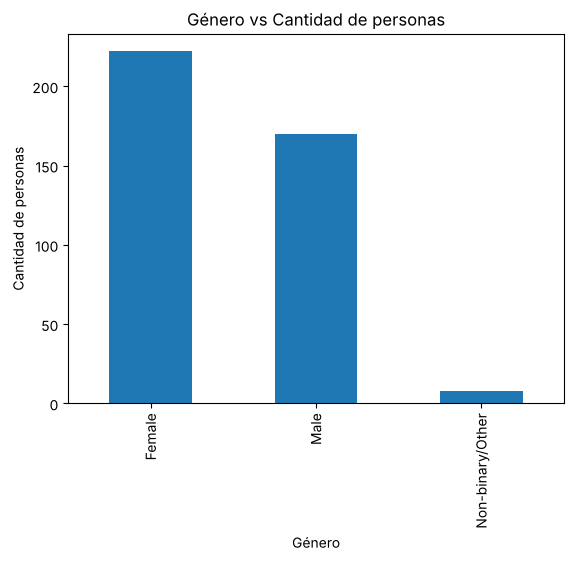

In [6]:
#Se cuentan los valores de cada categoría de la variable género
df["gender"].value_counts().plot(kind="bar")

#Se setea el título, las etiquetas y se despliega el gráfico
plt.title("Género vs Cantidad de personas")
plt.xlabel("Género")
plt.ylabel("Cantidad de personas")

plt.show()

#### Edad

A continuación se despliega el análisis sobre la variable edad, que consta de un histograma, un boxplot, y una tabla donde se enumeran medidas de dispersión y medidas de tendencia central.

In [7]:
#Se despliegan los estadísticos sobre la edad
df["age"].describe()

count    400.00000
mean      29.77750
std        7.46608
min       16.00000
25%       24.00000
50%       30.00000
75%       35.00000
max       60.00000
Name: age, dtype: float64

Text(0.5, 0, 'Edad')

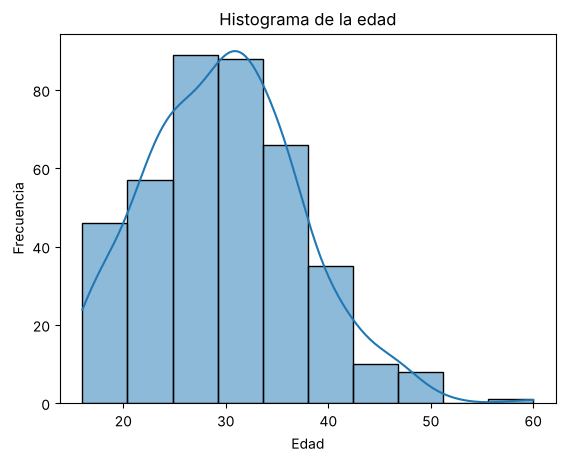

In [8]:
sns.histplot(x=df["age"], kde=True, bins=10)

plt.title("Histograma de la edad")
plt.ylabel("Frecuencia")
plt.xlabel("Edad")

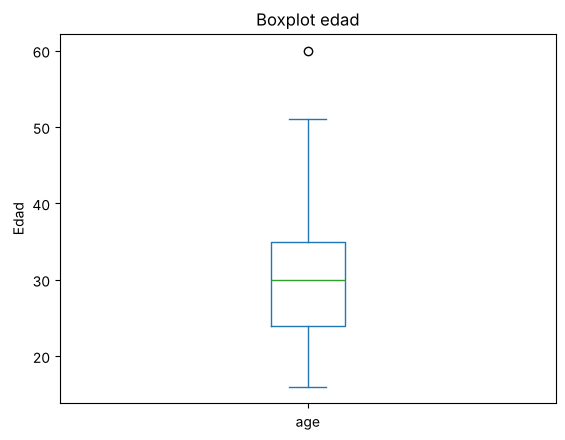

In [9]:
#Se fija la columna age para un boxplot
df["age"].plot(kind="box")

#Se setea el título del gráfico y se despliega
plt.title("Boxplot edad")
plt.ylabel("Edad")

plt.show()

De los resultados obtenidos se observa que la mayor concentración de la muestra se encuentra alrededor de los 30 años, se presenta una desviación estándar moderada de 7.5 puntos.

El histograma presenta asimetría positiva mostrando la presencia de personas de edad avanzada en la muestra.

### Ocupación y modalidad de trabajo

A continuación se analizarán las variables correspondientes al tipo de ocupación que tienen las personas de nuestra muestra y la modalidad de trabajo de ellas.

#### Ocupaciones

Se observa que la muestra está compuesta mayoritariamente por personas con empleo ya sea en una organización o con su propio emprendimiento. En menor proporción se hallan los estudiantes, mientras que la minoría corresponde a desempleados o retirados.

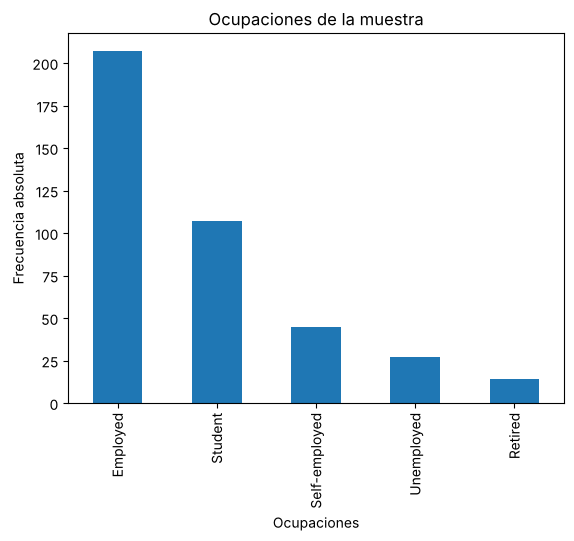

In [10]:
df["occupation"].value_counts().plot(kind="bar")

plt.title("Ocupaciones de la muestra")
plt.xlabel("Ocupaciones")
plt.ylabel("Frecuencia absoluta")

plt.show()

#### Modalidad de trabajo

En cuanto a la modalidad de trabajo, se encuentra una frecuencia similar entre la modalidad remota e híbrida, mientras que la modalidad presencial presenta una menor frecuencia. Resulta interesante que la ganadora sea la modalidad remota por sobre la presencial por tanta diferencia al menos en esta muestra.

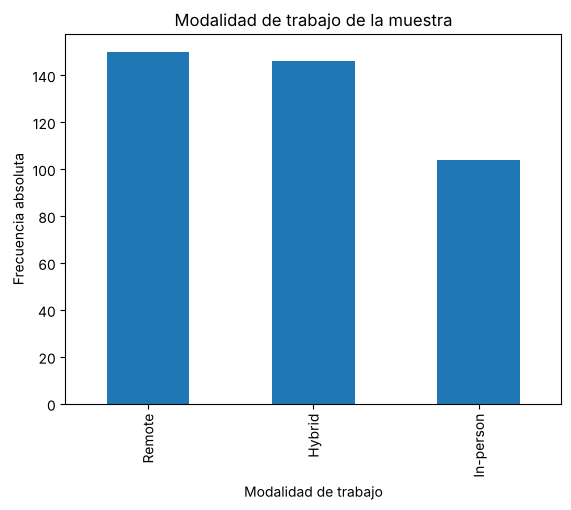

In [11]:
df["work_mode"].value_counts().plot(kind="bar")

plt.title("Modalidad de trabajo de la muestra")
plt.xlabel("Modalidad de trabajo")
plt.ylabel("Frecuencia absoluta")

plt.show()

### Tiempo y uso de la pantalla

En esta sección se analizarán las variables correspondientes a el tiempo y el uso que se le da a la pantalla, variables como tiempo de uso total de la pantalla, tiempo de uso en el trabajo y tiempo de uso en el ocio.

#### Tiempo de uso de pantalla

El uso de las pantallas presenta un promedio de 9.02 horas, con una desviación estándar de 2.49 que refleja el nivel de dispersión en los hábitos de consumo. Si bien el histograma confirma que la mayoría de los usuarios se agrupa cerca de la media, la presencia de valores atípicos en el extremo superior indica comportamientos digitales más extremos.

In [12]:
df["screen_time_hours"].describe()

count    400.000000
mean       9.024900
std        2.491058
min        1.000000
25%        7.372500
50%        9.090000
75%       10.495000
max       19.170000
Name: screen_time_hours, dtype: float64

Text(0.5, 0, 'Horas totales en pantalla')

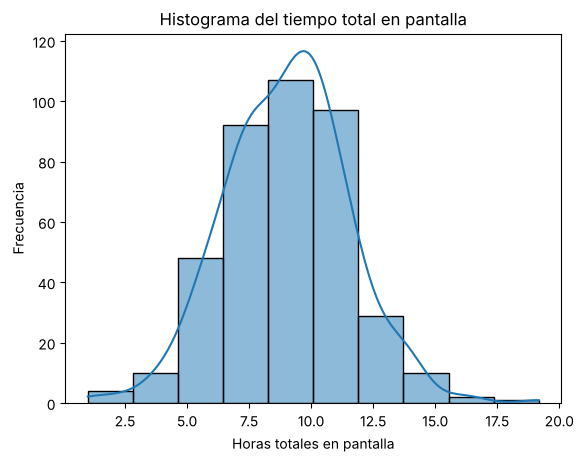

In [13]:
sns.histplot(x=df["screen_time_hours"], kde=True, bins=10)

plt.title("Histograma del tiempo total en pantalla")
plt.ylabel("Frecuencia")
plt.xlabel("Horas totales en pantalla")

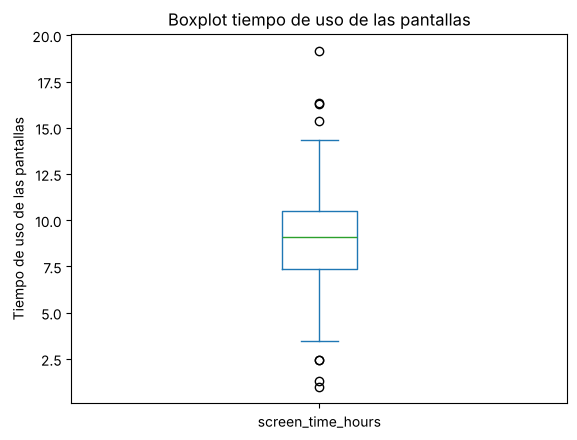

In [14]:
df["screen_time_hours"].plot(kind="box")

plt.title("Boxplot tiempo de uso de las pantallas")
plt.ylabel("Tiempo de uso de las pantallas")

plt.show()

#### Tiempo de uso en el trabajo

El uso de pantallas en el trabajo presenta una media de 2.18 horas y una desviación estándar de 1,93 siendo menor que el uso total, lo que indica que los datos están más concentrados. Esto sugiere que las horas de uso laboral son más homogéneas entre los individuos.

Sin embargo, al ver el boxplot se observan varios outliers por encima de las 7 horas, por lo que la muestra también esta compuesta de personas que cubren su jornada laboral completa al frente de una pantalla.

In [15]:
df["work_screen_hours"].describe()

count    400.000000
mean       2.183075
std        1.931321
min        0.110000
25%        0.695000
50%        1.455000
75%        3.012500
max       12.040000
Name: work_screen_hours, dtype: float64

Text(0.5, 0, 'Horas en pantalla en el trabajo')

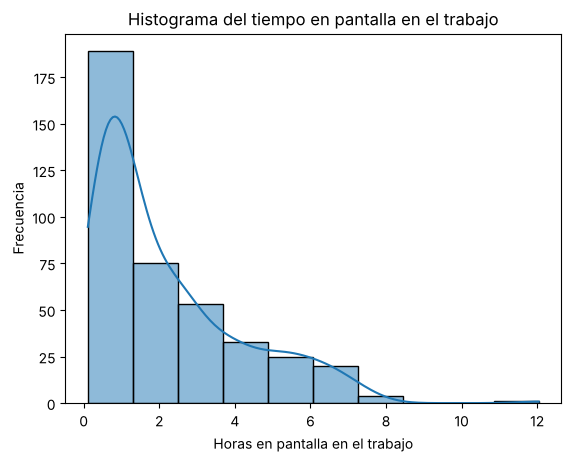

In [16]:
sns.histplot(x=df["work_screen_hours"], kde=True, bins=10)

plt.title("Histograma del tiempo en pantalla en el trabajo")
plt.ylabel("Frecuencia")
plt.xlabel("Horas en pantalla en el trabajo")

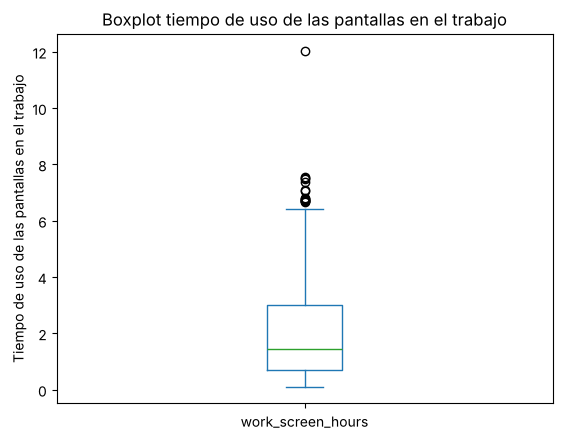

In [17]:
df["work_screen_hours"].plot(kind="box")

plt.title("Boxplot tiempo de uso de las pantallas en el trabajo")
plt.ylabel("Tiempo de uso de las pantallas en el trabajo")

plt.show()

#### Tiempo de uso para el ocio

El uso recreativo presenta una media de 6,84 horas y mayor desviación estándar de 2,22 puntos, lo que indica una mayor variabilidad entre los individuos. El histograma muestra una distribución más dispersa, sugiriendo que el ocio depende más del comportamiento individual.

Se observan unos cuantos outliers, uno por debajo de las dos horas, siendo aproximadamente de 1,7 horas, valor que nos parece bastante alto para ser un outlier por debajo del IQR del cuartil 1, y también outliers por encima de las 12 horas, que nos impacta conocer que en esta muestra hay personas que practicamente están todo el día usando el celular de forma ociosa.

In [18]:
df["leisure_screen_hours"].describe()

count    400.000000
mean       6.841825
std        2.220896
min        0.890000
25%        5.460000
50%        6.700000
75%        8.417500
max       13.350000
Name: leisure_screen_hours, dtype: float64

Text(0.5, 0, 'Horas en pantalla para el ocio')

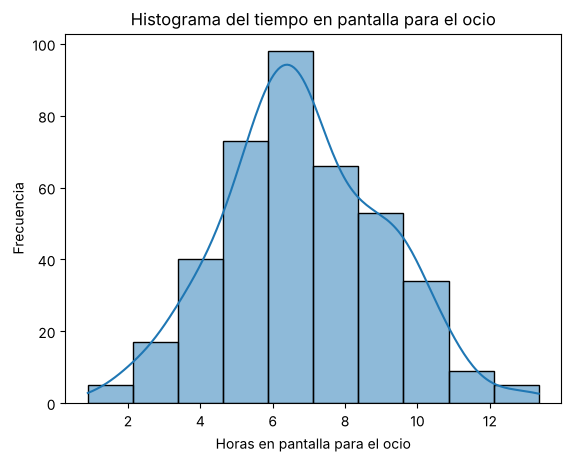

In [19]:
sns.histplot(x=df["leisure_screen_hours"], kde=True, bins=10)

plt.title("Histograma del tiempo en pantalla para el ocio")
plt.ylabel("Frecuencia")
plt.xlabel("Horas en pantalla para el ocio")

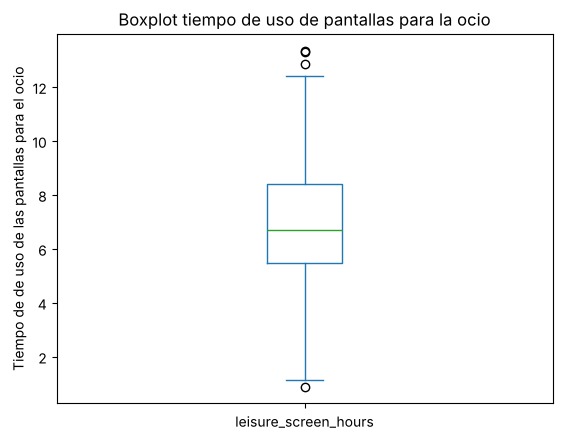

In [20]:
df["leisure_screen_hours"].plot(kind="box")

plt.title("Boxplot tiempo de uso de pantallas para la ocio")
plt.ylabel("Tiempo de de uso de las pantallas para el ocio")

plt.show()

### Indicadores del sueño

En esta sección se analizarán las variables relacionadas al sueño, como horas de sueño y calidad del sueño.

#### Horas de sueño

Respecto a las horas de sueño, las medidas de tendencia central muestran que la media tiene un valor muy similar al de la mediana, con una desviación estándar de aproximadamente 0.85, lo que indica una baja dispersión de los datos. Esto se puede apreciar visualmente en el histograma, donde la mayoría de los registros están agrupados estrechamente alrededor de la media, sugiriendo una distribución aproximadamente normal. Tal simetría es respaldada por el diagrama de caja, el cual confirma una concentración equilibrada de los datos en el centro, con solo un dato “outlier” cercano a 10.

In [21]:
df["sleep_hours"].describe()

count    400.000000
mean       7.013175
std        0.852421
min        4.640000
25%        6.397500
50%        7.030000
75%        7.640000
max        9.740000
Name: sleep_hours, dtype: float64

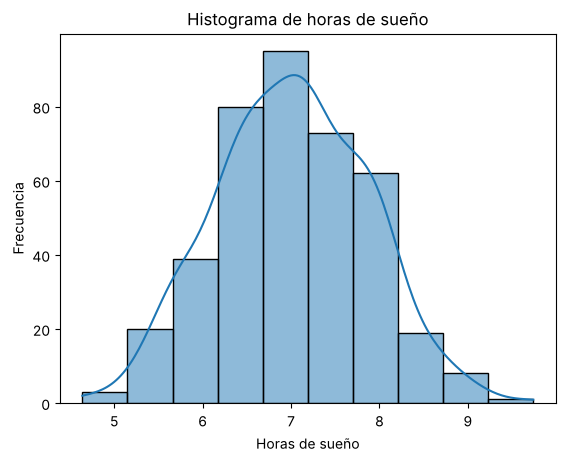

In [22]:
sns.histplot(x="sleep_hours", bins=10, kde=True, data = df )

plt.title("Histograma de horas de sueño")
plt.ylabel("Frecuencia")
plt.xlabel("Horas de sueño")

plt.show()

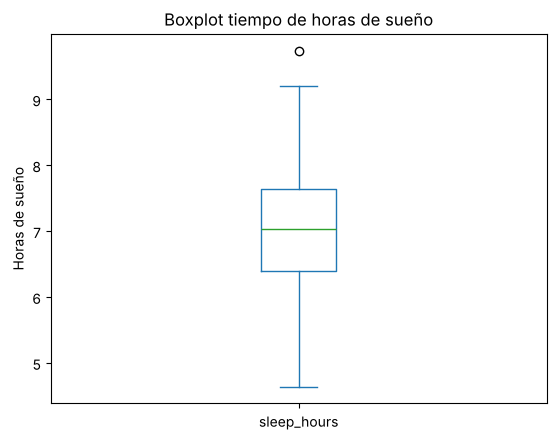

In [23]:
df["sleep_hours"].plot(kind="box")

plt.title("Boxplot tiempo de horas de sueño")
plt.ylabel("Horas de sueño")

plt.show()

#### Calidad del sueño

En cuanto a la calidad del sueño, la distribución observada indica una clara tendencia negativa en el descanso de los encuestados. La gran mayoría asegura que su calidad de sueño es de nivel 1, es decir, muy pobre. A partir de este punto, la frecuencia de las respuestas va disminuyendo progresivamente a medida que aumenta el nivel de calidad, evidenciando una falta de sueño reparador, en gran parte de la muestra.

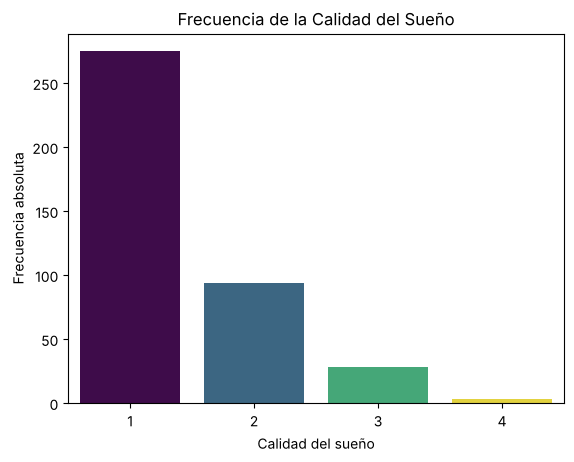

In [24]:
sns.countplot(x="sleep_quality_1_5", hue="sleep_quality_1_5", palette="viridis", legend=False, data=df)

plt.title("Frecuencia de la Calidad del Sueño")
plt.ylabel("Frecuencia absoluta")
plt.xlabel("Calidad del sueño")

plt.show()

### Indicadores de salud mental

En esta sección se analizarán las variables correspondientes al estilo de vida de la muestra, las cuales corresponden a las columnas nivel de estrés y bienestar mental autorreportado por la muestra.

#### Bienestar de la salud mental

Se puede observar que los valores se concentran en torno a un rango bajo (entre 0 y 20 puntos), lo que sugiere que la mayor parte de la muestra presenta niveles reducidos de bienestar mental y que existen pocos individuos con puntajes altos (cercanos a 100).

Nos parece impactante que los outliers se encuentran desde los 70 puntos en adelante, lo que sugiere que las personas que tienen una buena salud mental autopercibida son minoria, y que la muestra está compuesta por gente con pobre salud mental.

In [25]:
df["mental_wellness_index_0_100"].describe()

count    400.000000
mean      20.326750
std       20.376793
min        0.000000
25%        3.675000
50%       14.800000
75%       30.650000
max       97.000000
Name: mental_wellness_index_0_100, dtype: float64

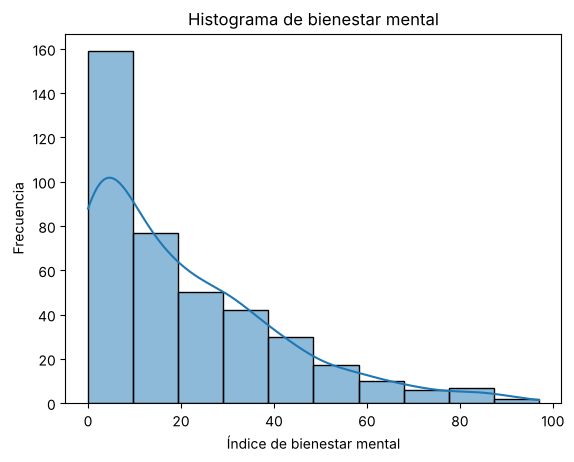

In [26]:
sns.histplot(x="mental_wellness_index_0_100", bins=10, kde=True, data = df )

plt.title("Histograma de bienestar mental")
plt.ylabel("Frecuencia")
plt.xlabel("Índice de bienestar mental")

plt.show()

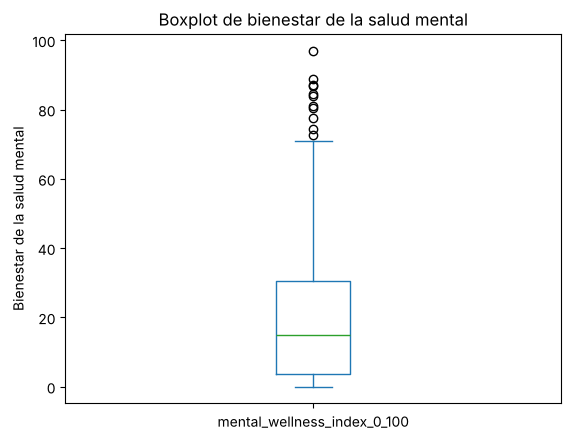

In [27]:
df["mental_wellness_index_0_100"].plot(kind="box")

plt.title("Boxplot de bienestar de la salud mental")
plt.ylabel("Bienestar de la salud mental")

plt.show()

#### Niveles de estrés

Los datos sobre el nivel de estrés presentan una media cercana a la mediana y una desviación estándar aproximada de 2.09, indicando cierta dispersión en las respuestas. Sin embargo, al analizar visualmente la distribución, destaca un fenómeno particular, dado que una inmensa cantidad de los individuos evalúa su nivel de estrés en el valor máximo. Esto genera una clara distribución asimétrica negativa. El diagrama de caja complementa y reafirma este hallazgo, mostrando cómo los valores se agrupan en niveles altos, dejando una única cola, que se prolonga hacia los niveles más bajos de estrés.

In [28]:
df["stress_level_0_10"].describe()

count    400.000000
mean       8.150500
std        2.094844
min        0.000000
25%        6.900000
50%        8.800000
75%       10.000000
max       10.000000
Name: stress_level_0_10, dtype: float64

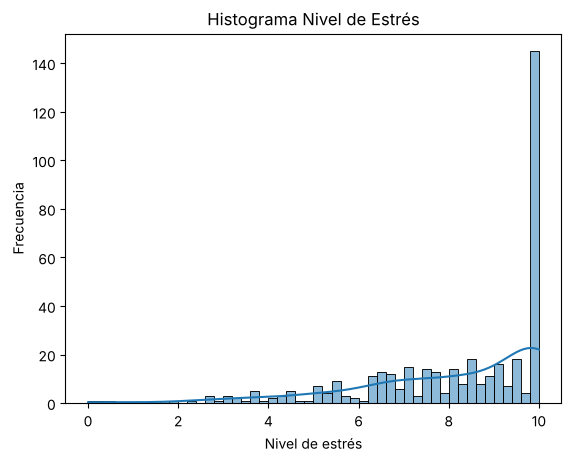

In [29]:
sns.histplot(x="stress_level_0_10", bins=50, kde=True, data = df )

plt.title("Histograma Nivel de Estrés")
plt.ylabel("Frecuencia")
plt.xlabel("Nivel de estrés")

plt.show()

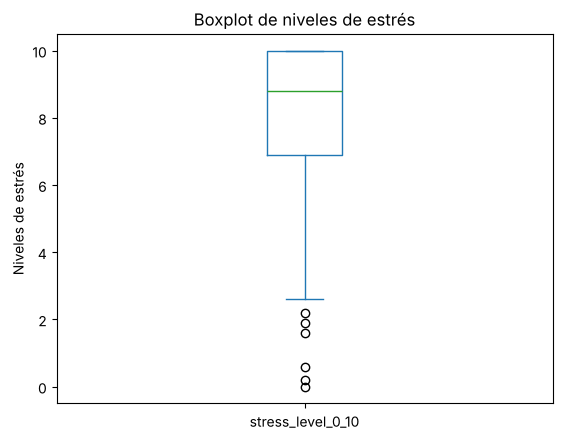

In [30]:
df["stress_level_0_10"].plot(kind="box")

plt.title("Boxplot de niveles de estrés")
plt.ylabel("Niveles de estrés")

plt.show()

### Estilo de vida

A continuación se analizarán las variables correspondientes al estilo de vida de la muestra, donde se incluye el tiempo invertido en hacer ejercicio, el tiempo invertido en socializar fuera de las pantallas y la productividad autorreportada por el individuo.

#### Tiempo de ejercicio por semana

El tiempo promedio de ejercicio por semana de 109 minutos, sugiere que la muestra realiza en promedio 15,7 minutos de ejercicio por día, lo que corresponde a una cantidad moderada de ejercicio al día.

El rango intercuartílico de 99 minutos es bastante alto, lo que muestra una alta dispersión de los datos en su centro a pesar de tener medias y medianas similares.

Se observa un outlier de aproximadamente de 350 minutos, lo que impulsa la desviación estandar a un valor mayor alcanzando los 70 puntos.

In [31]:
df["exercise_minutes_per_week"].describe()

count    400.000000
mean     109.810000
std       70.007045
min        0.000000
25%       58.000000
50%      103.000000
75%      157.000000
max      372.000000
Name: exercise_minutes_per_week, dtype: float64

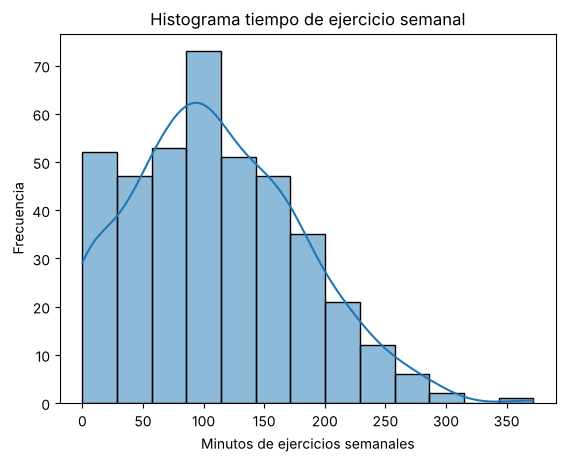

In [32]:
sns.histplot(x="exercise_minutes_per_week", bins=13, kde=True, data = df )

plt.title("Histograma tiempo de ejercicio semanal")
plt.ylabel("Frecuencia")
plt.xlabel("Minutos de ejercicios semanales")

plt.show()

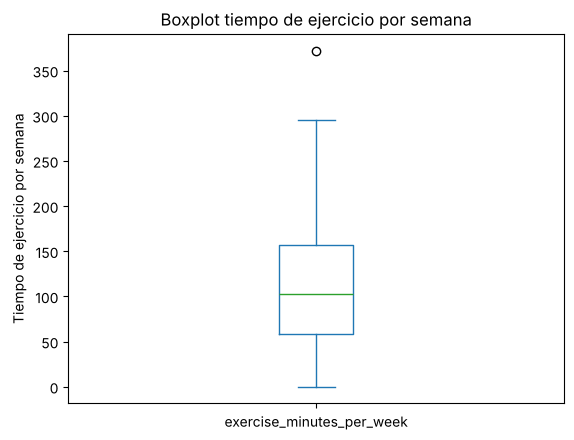

In [33]:
df["exercise_minutes_per_week"].plot(kind="box")

plt.title("Boxplot tiempo de ejercicio por semana")
plt.ylabel("Tiempo de ejercicio por semana")

plt.show()

#### Productividad

En cuanto a la productividad autorreportada, encontramos que en general, los datos presentan una desviación moderada, sin embargo el boxplot revela que existen varios outliers, los cuales pueden aumentar la desviación estándar obtenida.

El histograma muestra una cola hacia la derecha, lo que sugiere que los datos tienden a dispersarse a los altos niveles de productividad.

In [34]:
df["productivity_0_100"].describe()

count    400.000000
mean      54.306500
std       15.020054
min       20.600000
25%       43.600000
50%       51.750000
75%       63.000000
max      100.000000
Name: productivity_0_100, dtype: float64

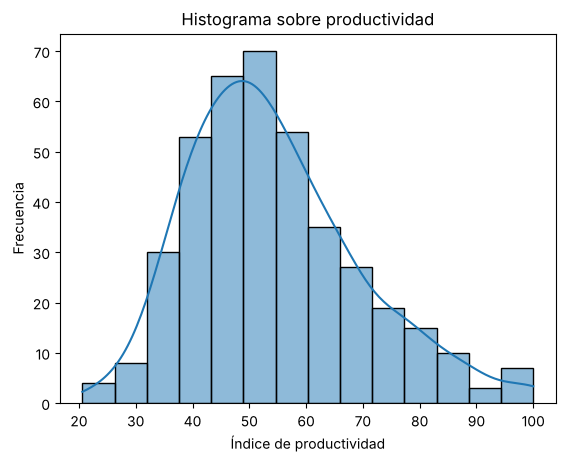

In [35]:
sns.histplot(x="productivity_0_100", bins=14, kde=True, data = df )

plt.title("Histograma sobre productividad")
plt.ylabel("Frecuencia")
plt.xlabel("Índice de productividad")

plt.show()

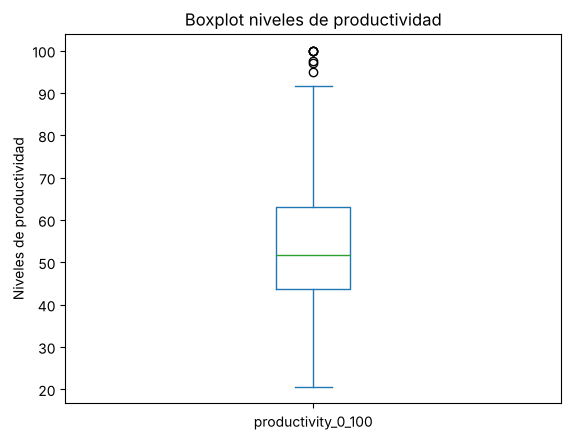

In [36]:
df["productivity_0_100"].plot(kind="box")

plt.title("Boxplot niveles de productividad")
plt.ylabel("Niveles de productividad")

plt.show()

#### Interacción social semanal

La variable correspondiente a las horas de interacción social semanal, presenta una media de 7.91 horas, muy cercana a su mediana, que posee un valor de 7.75 horas. En cuanto a la dispersión, se observa una desviación estándar de 4.91 horas, lo que indica que los datos están algo dispersos. Es relevante destacar la amplitud del rango de respuestas, que va desde la nula socialización, hasta unos valores atípicos sobre las 20 horas, que llegan a un máximo de 23.9 horas semanales. Además, el histograma pone en evidencia una distribución asimétrica positiva, reafirmando que la mayor cantidad de los datos se concentran en valores bajos.

In [37]:
df["social_hours_per_week"].describe()

count    400.000000
mean       7.905000
std        4.909632
min        0.000000
25%        4.575000
50%        7.750000
75%       11.025000
max       23.900000
Name: social_hours_per_week, dtype: float64

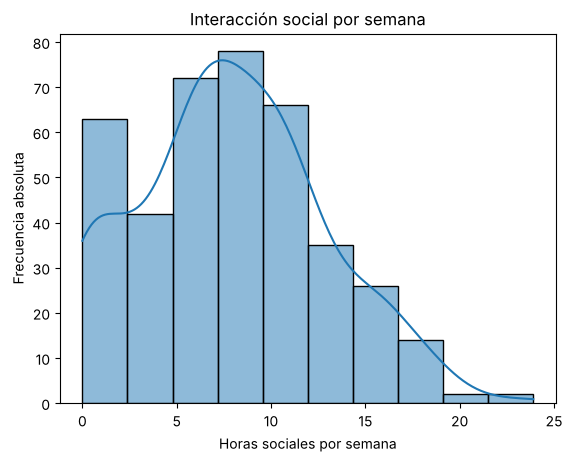

In [38]:
sns.histplot(x="social_hours_per_week", bins=10, kde=True, data = df )

plt.title("Interacción social por semana")
plt.ylabel("Frecuencia absoluta")
plt.xlabel("Horas sociales por semana")

plt.show()

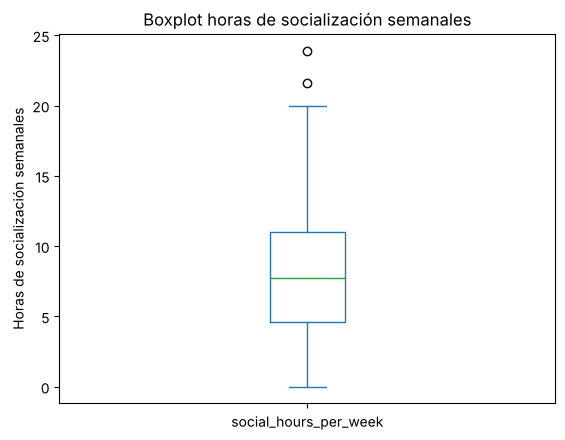

In [39]:
df["social_hours_per_week"].plot(kind="box")

plt.title("Boxplot horas de socialización semanales")
plt.ylabel("Horas de socialización semanales")

plt.show()

## Análisis multivariado

### Matriz de correlación

Se despliega la matriz de correlación para hacer un análisis general de las relaciones lineales entre las columnas

Nota: El siguiente recurso fue obtenido en ChatGPT con el siguiente prompt. "Hazme una matriz de correlación que a parte de usar la paleta de colores, muestre los números dentro de las casillas redondeados a dos decimales".

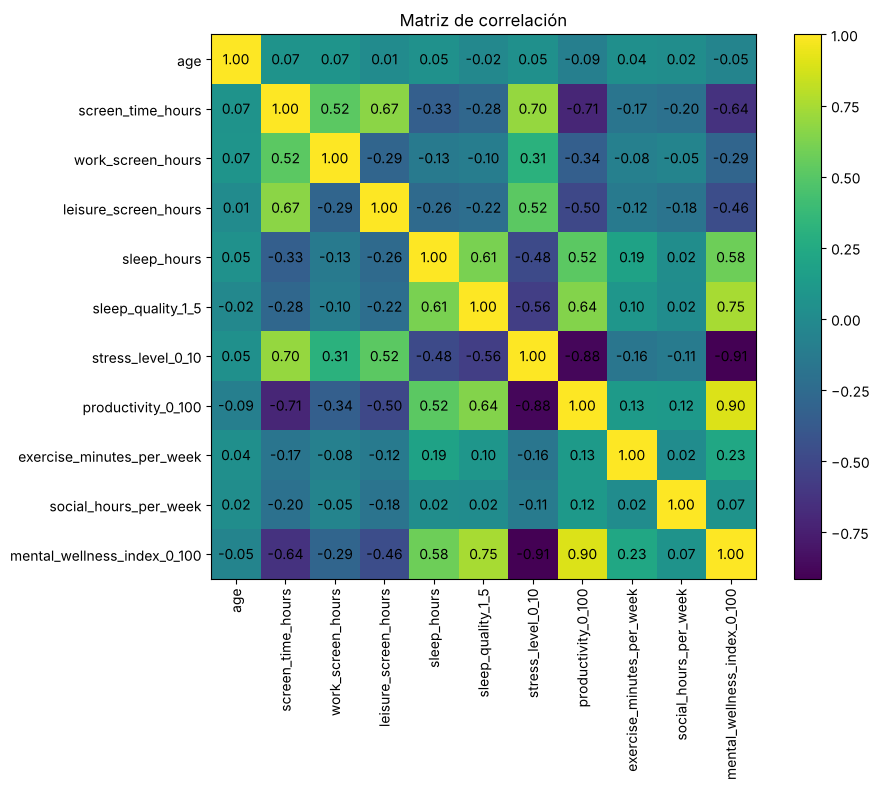

In [40]:
# Matriz de correlación
corr = df.corr(numeric_only=True)

# Crear figura
plt.figure(figsize=(10, 8))

# Heatmap
plt.imshow(corr, cmap = "viridis")
plt.colorbar()

# Etiquetas
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

# Valores dentro de cada celda
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha='center', va='center')

plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

### Bienestar mental vs calidad del sueño


Se encuentra una relación entre la calidad del sueño y el bienestar mental, donde a mayor calidad del sueño, mejor bienestar mental. Los boxplots muestran que a medida que crece el bienestar mental, también lo hace la mediana y la distribución de los datos del bienestar mental.

Sin embargo, en el nivel más bajo de calidad del sueño, podemos observar que tiene algunos outliers, lo que indica que, a pesar de presentar mala calidad del sueño, existen personas que reportan un nivel de bienestar mental medio, esto sugiere que el bienestar mental no solo depende de la calidad del sueño.

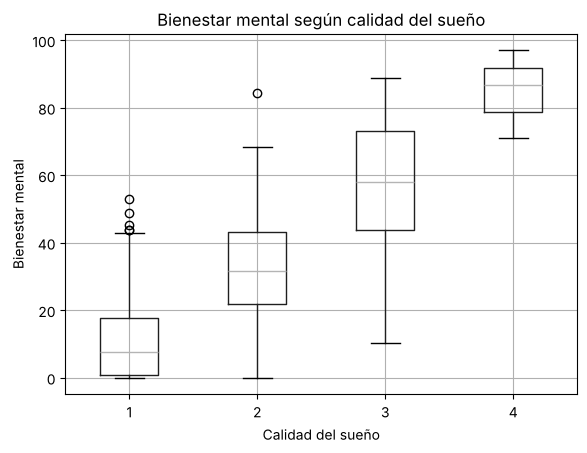

In [41]:
df.boxplot(column="mental_wellness_index_0_100", by="sleep_quality_1_5")

plt.title("Bienestar mental según calidad del sueño")
plt.suptitle("")
plt.xlabel("Calidad del sueño")
plt.ylabel("Bienestar mental")

plt.show()

### Bienestar mental vs productividad

Al realizar un scatterplot con las variables de productividad y bienestar mental, se puede observar que tienen una relación positiva, donde a mayores niveles de productividad, mayores niveles de bienestar mental.

No obstante, se observan valores en 0 de bienestar mental para niveles de productividad un poco más alto, por lo que se categorizará el nivel de productividad en muy bajo, bajo, medio, alto y muy alto y se construyen distintos boxplots para corroborar la información.

Hecho el gráfico, se puede observar primero que nadie reporta un nivel de productividad muy bajo, luego, con el boxplot del nivel bajo de productividad se observa que su primer cuartil y mediana se halla sobre el cero y varios outliers que no superan los 20 puntos de bienestar, por lo que la gente que presenta una baja productividad tiene un bienestar mental bajo.

<Axes: xlabel='mental_wellness_index_0_100', ylabel='productivity_0_100'>

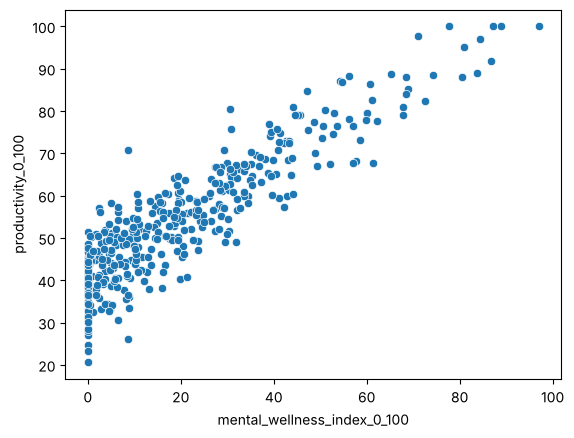

In [42]:
sns.scatterplot(x="mental_wellness_index_0_100", y="productivity_0_100", data=df)

Nota: El siguiente código fue extraído de ChatGPT con el siguiente prompt "Ayúdame a construir distintos boxplots en el mismo gráfico, primero, necesito categorizar la columna de productivity_0_100 en muy baja, baja, media, alta y muy alta, con los rangos 0-20, 21-40, 41-60, 61-80 y 81-100. (Necesito que sean de distintos colores para categorizarla bien)". Disclaimer: Este código puede ser reproducido para algún otro análisis útil entre columnas.

<Figure size 1000x600 with 0 Axes>

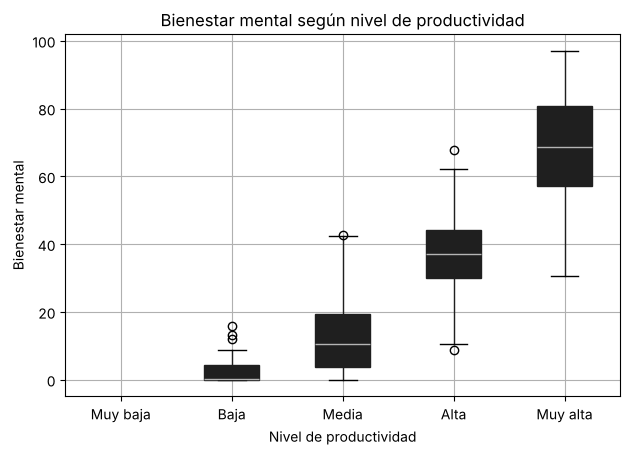

In [43]:
# 1. Crear categorías de productividad
bins = [0, 20, 40, 60, 80, 100]
labels = ["Muy baja", "Baja", "Media", "Alta", "Muy alta"]

df["productivity_cat"] = pd.cut(
    df["productivity_0_100"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# 2. Asegurar orden correcto
df["productivity_cat"] = pd.Categorical(
    df["productivity_cat"],
    categories=labels,
    ordered=True
)

# 3. Crear boxplot con colores
plt.figure(figsize=(10,6))

box = df.boxplot(
    column="mental_wellness_index_0_100",
    by="productivity_cat",
    patch_artist=True
)

# Colores tipo gradiente (de peor a mejor)
colors = ["#d73027", "#fc8d59", "#fee08b", "#91cf60", "#1a9850"]

for patch, color in zip(box.artists, colors):
    patch.set_facecolor(color)

# 4. Detalles del gráfico
plt.title("Bienestar mental según nivel de productividad")
plt.suptitle("")
plt.xlabel("Nivel de productividad")
plt.ylabel("Bienestar mental")

plt.tight_layout()
plt.show()

### Nivel de estrés vs productividad

A continuación, se decidió categorizar la variable de nivel de estrés, por motivos de visualización gráfica y debido a su alta asimetría, que concentraba demasiados valores cercanos a 10. Esta división permite separar el estrés manejable, que va de 0 a 6, de las zonas de riesgo entre 7 y 8, aislando de manera específica el extremo más crítico, que supera el nivel 9.

In [44]:
limites_nivel_estres = [-1, 3, 6, 8, 10]
categorias_estres = ["Bajo", "Medio", "Alto", "Crítico"]
df['stress_level_categorized'] = pd.cut(df['stress_level_0_10'], bins=limites_nivel_estres, labels=categorias_estres)

Al evaluar la relación entre el nivel de estrés y la productividad, se observa una clara tendencia negativa generalizada. Sin embargo, al segmentar los datos según la calidad del sueño, es posible notar que los individuos con bajo nivel de sueño presentan mayores niveles de estrés y menor productividad, concentrándose hacia el costado inferior derecho del gráfico. Mientras que quienes tienen mayor calidad de sueño, suelen mostrar una mayor productividad y menor nivel de estrés. Esto sugiere que un estrés alto afecta de manera negativa a la productividad, donde la calidad del sueño parece amplificar este fenómeno.

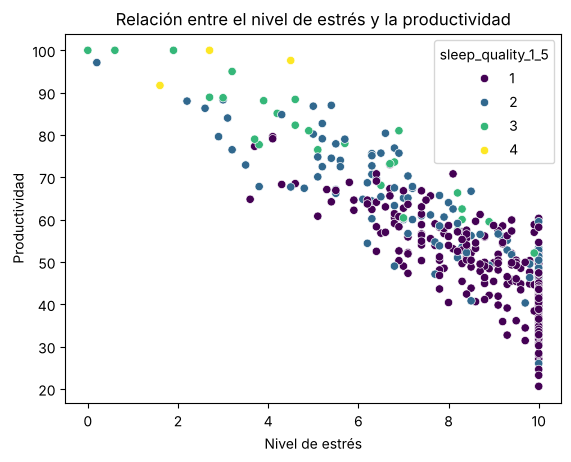

In [45]:
sns.scatterplot(x="stress_level_0_10", y="productivity_0_100", hue="sleep_quality_1_5", palette="viridis", data=df)

plt.title("Relación entre el nivel de estrés y la productividad")
plt.xlabel("Nivel de estrés")
plt.ylabel("Productividad")

plt.show()

### Niveles de estrés vs horas de sueño

Respecto a la distribución de las horas de sueño diarias diferenciadas por el nivel de estrés de los usuarios, se presentan variaciones claras en cada categoría. En el grupo con estrés bajo, la distribución muestra una concentración casi superior a las 7 horas de sueño. Sin embargo, a medida que el estrés aumenta hacia los niveles alto y crítico, la campana se desplaza visiblemente hacia la izquierda. Esto indica que el estrés extremo reduce significativamente la cantidad absoluta de horas dormidas.

Nota: El siguiente código fue obtenido en ChatGPT utilizando el siguiente prompt: "Haz un ridgeplot para un dataset con las variables “sleep_hours” y “stress_level_categorized”.

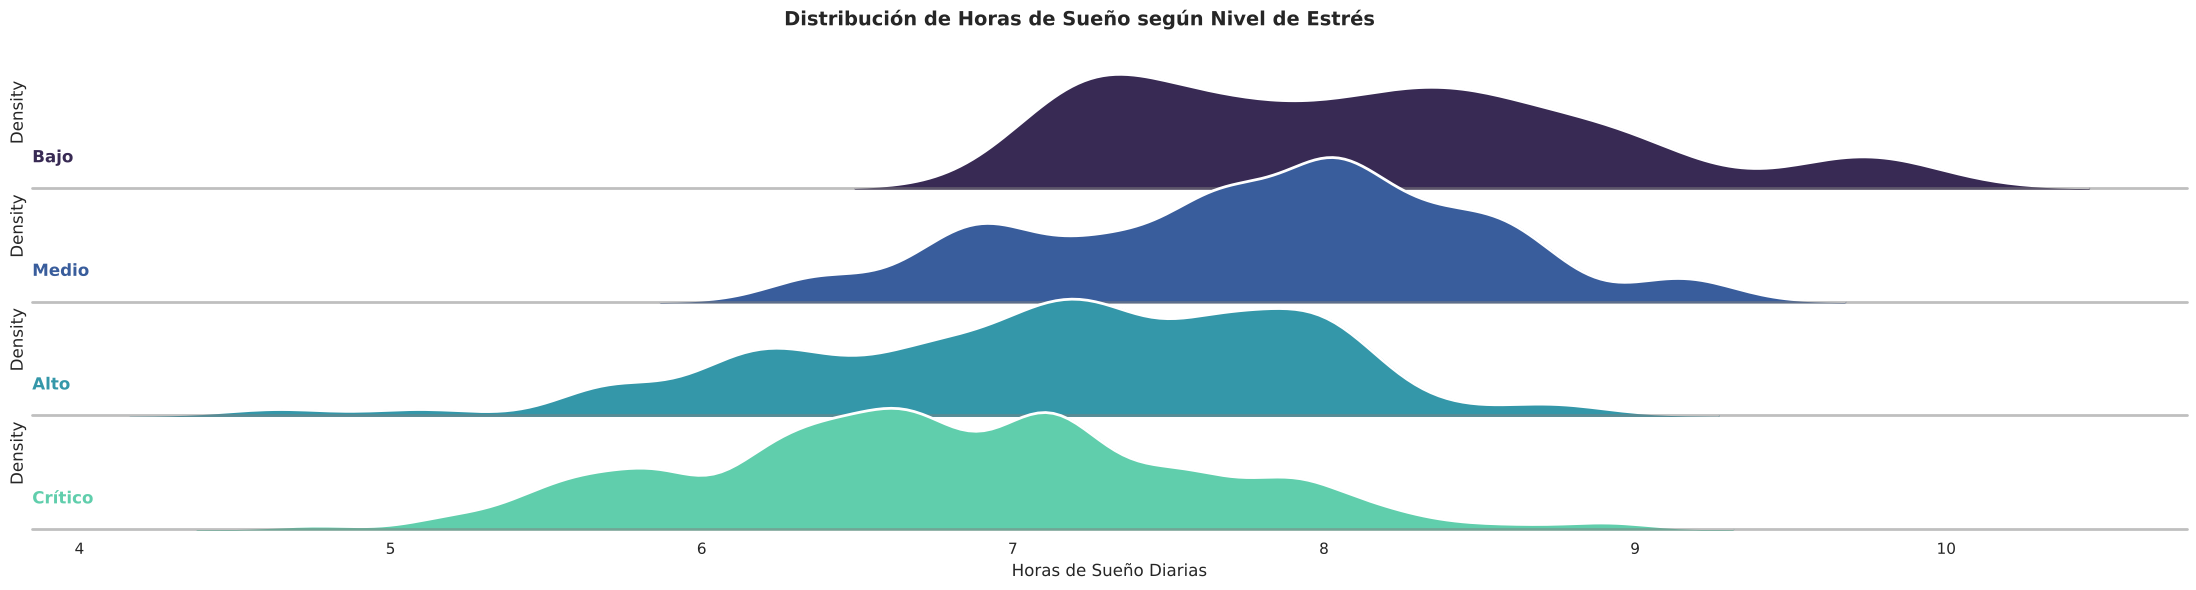

In [46]:
sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

# Creamos el FacetGrid: una "rejilla" para cada categoría de estrés.
# 'row' separa por categorías, 'hue' asigna colores, 'aspect' da el ancho.
g = sns.FacetGrid(df, row="stress_level_categorized", hue="stress_level_categorized", aspect=15, height=1.5, palette="mako")

# Dibujamos las "montañas" (KDE plots) de Horas de Sueño en cada rejilla.
# 'clip_on=False' permite que las montañas sobresalgan un poco, 'fill=True' las rellena.
g.map(sns.kdeplot, "sleep_hours", bw_adjust=.5, clip_on=False, fill=True, alpha=1, linewidth=1.5)

# Dibujamos una línea blanca en la base de cada montaña para separarlas mejor.
g.map(sns.kdeplot, "sleep_hours", clip_on=False, color="w", lw=2, bw_adjust=.5)

# Dibujamos una línea horizontal gris en la base de todo el gráfico.
g.map(plt.axhline, y=0, lw=2, clip_on=False, color='gray', alpha=0.5)


# Función para poner los nombres de las categorías a la izquierda de cada montaña.
def label(x, color, label):
    ax = plt.gca()
    # x=0 lo pega a la izquierda, y=0.2 lo sube un poco de la línea base
    ax.text(0, .2, label, fontweight="bold", color=color,
            ha="left", va="center", transform=ax.transAxes, fontsize=12)

# Mapeamos la función label a cada fila.
g.map(label, "stress_level_categorized")

# Ajustamos para que las montañas se solapen ligeramente entre sí (overlap).
# hspace=-.25 es el valor mágico para el Ridge Plot.
g.fig.subplots_adjust(hspace=-.25)

# Quitamos los títulos por defecto, ejes innecesarios y limpiamos el look.
g.set_titles("")
g.set(yticks=[])
g.despine(bottom=True, left=True)

plt.xlabel("Horas de Sueño Diarias", fontsize=12)
plt.suptitle('Distribución de Horas de Sueño según Nivel de Estrés', fontsize=14, fontweight='bold', y=0.98)

plt.show()

### Bienestar mental vs horas en pantalla

Al analizar el comportamiento entre el índice de bienestar mental y las horas en pantalla, se aprecia una tendencia negativa entre ambas variables. Además es posible notar que, a mayor calidad del sueño, los individuos presentan un mejor nivel de bienestar mental y un menor uso de pantallas. En consecuencia, pareciera que un mejor bienestar, viene dado por una menor exposición a las pantallas, y también por una mejor calidad del sueño.

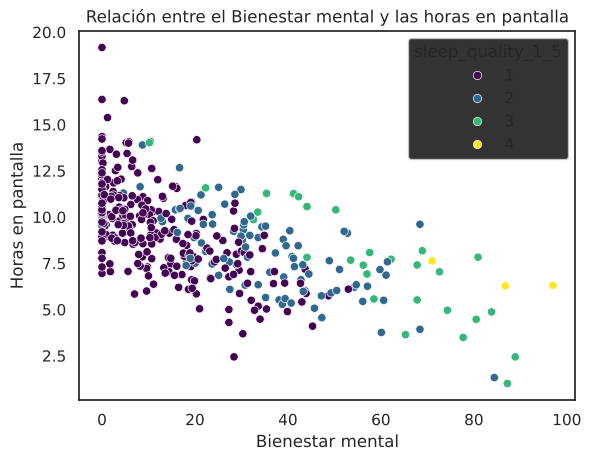

In [47]:
sns.scatterplot(x="mental_wellness_index_0_100", y="screen_time_hours", hue="sleep_quality_1_5", palette="viridis", data=df)

plt.title("Relación entre el Bienestar mental y las horas en pantalla")
plt.xlabel("Bienestar mental")
plt.ylabel("Horas en pantalla")

plt.show()

### Horas de interacción social vs bienestar mental

En el caso de las horas de interacción social por semana y el índice de bienestar mental, los datos revelan un patrón fuertemente contraintuitivo. A diferencia de lo que se podría asumir de forma tradicional, no existe una correlación positiva que indique que a mayor socialización, mejor estado de salud mental. Este hallazgo sugiere que, en esta muestra, la cantidad de horas sociales no se traduce en calidad de vida.

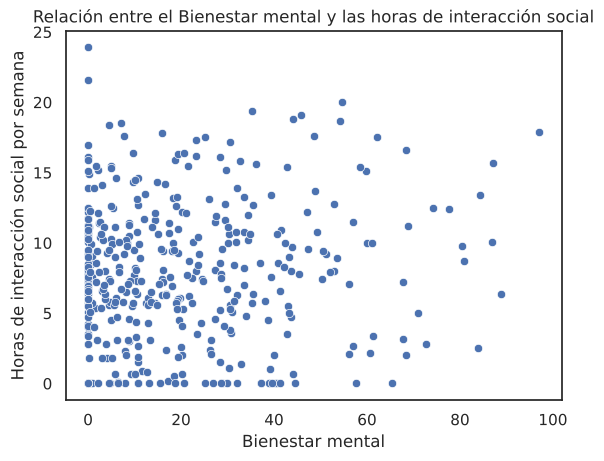

In [48]:
sns.scatterplot(x="mental_wellness_index_0_100", y="social_hours_per_week", data=df)

plt.title("Relación entre el Bienestar mental y las horas de interacción social")
plt.xlabel("Bienestar mental")
plt.ylabel("Horas de interacción social por semana")

plt.show()

### Bienestar mental y modalidades de trabajo

Al comparar las distribuciones del índice de bienestar mental segmentadas por la modalidad de trabajo mediante un diagrama de caja, se observan diferencias sutiles. Lo primero que destaca es que las tres medianas son bajas, ninguna supera los 25 puntos de 100, lo que confirma un estado generalizado de mala salud mental. Sin embargo, al comparar, la modalidad en persona presenta una mediana y un rango intercuartil ligeramente superiores al resto.Esto sugiere que, aunque el estado mental es bajo para todos, la modalidad en persona parece ofrecer una mayor variabilidad de experiencias que quizás permite mejores puntajes, mientras que la modalidad remota concentra a la población en niveles muy bajos de bienestar.

/tmp/ipykernel_405/655688237.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='mental_wellness_index_0_100', y='work_mode', palette='viridis', data=df)


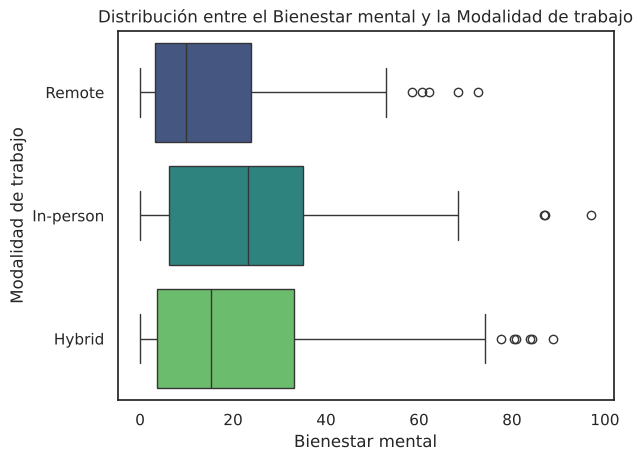

In [49]:
sns.boxplot(x='mental_wellness_index_0_100', y='work_mode', palette='viridis', data=df)

plt.title("Distribución entre el Bienestar mental y la Modalidad de trabajo")
plt.xlabel("Bienestar mental")
plt.ylabel("Modalidad de trabajo")

plt.show()

### Horas de sueño vs bienestar mental

Para la gráfica de horas de sueño en comparación con el índice de bienestar mental, se evidencia un comportamiento creciente, donde el nivel de estrés parece incidir claramente en una mejor calidad de vida y un mayor descanso. Es decir, que los niveles de estrés afectan tanto a las horas de sueño como al bienestar mental, demostrando que a menor nivel de estrés, se obtienen mejores resultados en las otras dos variables.

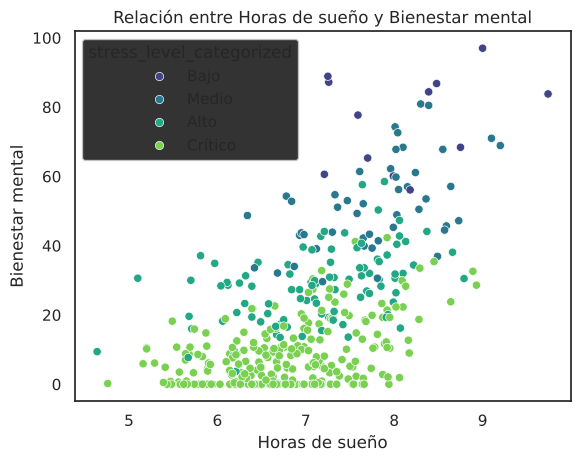

In [50]:
sns.scatterplot(x="sleep_hours", y="mental_wellness_index_0_100", hue="stress_level_categorized", palette="viridis", data=df)

plt.title("Relación entre Horas de sueño y Bienestar mental")
plt.xlabel("Horas de sueño")
plt.ylabel("Bienestar mental")

plt.show()

Una situación similar al caso anterior, sucede al comparar las variables de horas de sueño y productividad. Donde a menor nivel de estrés, mejores son los resultados obtenidos.

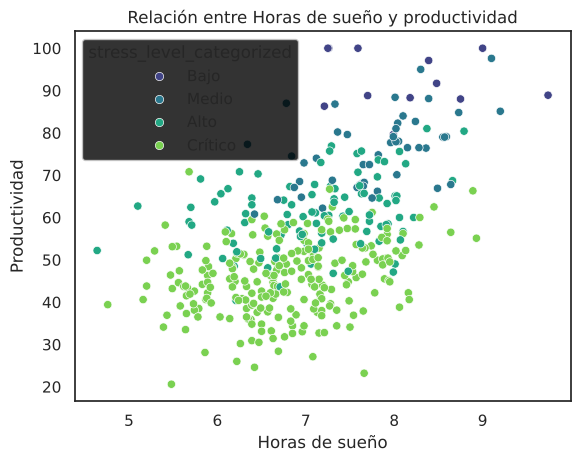

In [51]:
sns.scatterplot(x="sleep_hours", y="productivity_0_100", hue="stress_level_categorized", palette="viridis", data=df)

plt.title("Relación entre Horas de sueño y productividad")
plt.xlabel("Horas de sueño")
plt.ylabel("Productividad")

plt.show()

### Calidad de sueño vs horas en pantalla

Al examinar la calidad del sueño junto a las horas en pantalla, surge un patrón claro, donde, a mejor calidad de descanso, menor exposición a pantallas. La mediana cae de casi 10 horas diarias en el grupo con peor sueño a menos de 7 horas en el nivel 4. Además, el grupo con peor descanso muestra una alta dispersión y desregulación extrema en sus hábitos, mientras que quienes duermen mejor mantienen un uso de pantallas mucho más compacto y constante. Por lo tanto, un mal descanso se asocia al exceso de horas de pantalla.

/tmp/ipykernel_405/891087983.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="sleep_quality_1_5", y="screen_time_hours", palette="viridis", data=df)


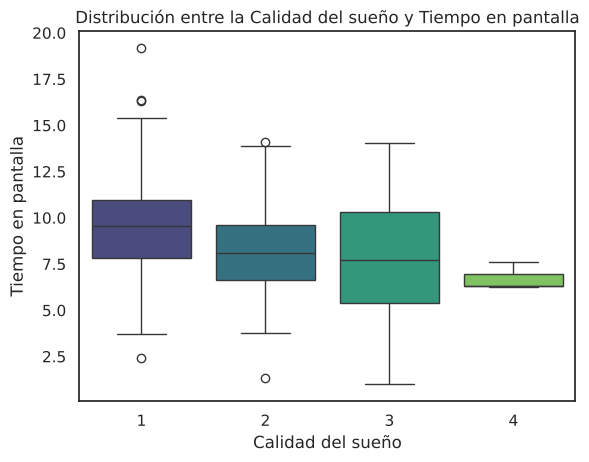

In [52]:
sns.boxplot(x="sleep_quality_1_5", y="screen_time_hours", palette="viridis", data=df)

plt.title("Distribución entre la Calidad del sueño y Tiempo en pantalla")
plt.xlabel("Calidad del sueño")
plt.ylabel("Tiempo en pantalla")

plt.show()

### Minutos de ejercicio vs calidad del sueño

En cuanto a los minutos de ejercicio semanal con la calidad del sueño, se observa un salto drástico en el grupo con mejor descanso. Los individuos con calidad de sueño del 1 al 3 presentan hábitos de ejercicio sumamente erráticos: sus medianas rondan apenas los 100 minutos y su dispersión es grande. Sin embargo, el grupo con calidad de sueño nivel 4 rompe este patrón de inconstancia, dado que su caja es muy compacta y elevada, mostrando una mediana de 200 minutos y un piso mínimo de 150 minutos semanales.

/tmp/ipykernel_405/4133567025.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="sleep_quality_1_5", y="exercise_minutes_per_week", palette="viridis", data=df)


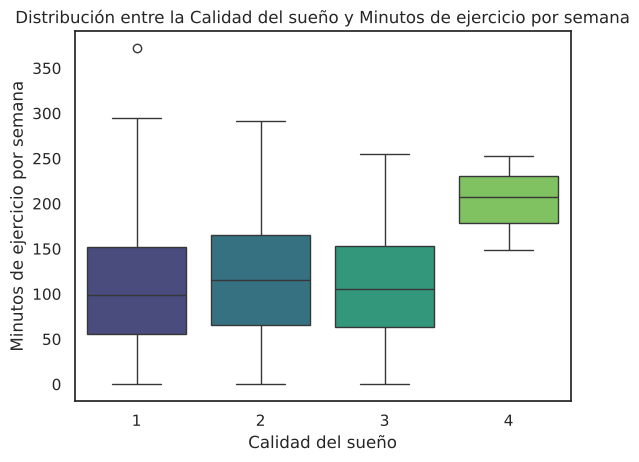

In [53]:
sns.boxplot(x="sleep_quality_1_5", y="exercise_minutes_per_week", palette="viridis", data=df)

plt.title("Distribución entre la Calidad del sueño y Minutos de ejercicio por semana")
plt.xlabel("Calidad del sueño")
plt.ylabel("Minutos de ejercicio por semana")

plt.show()

/tmp/ipykernel_405/2705029247.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sleep_quality_1_5', y='productivity_0_100', palette='viridis', data=df)


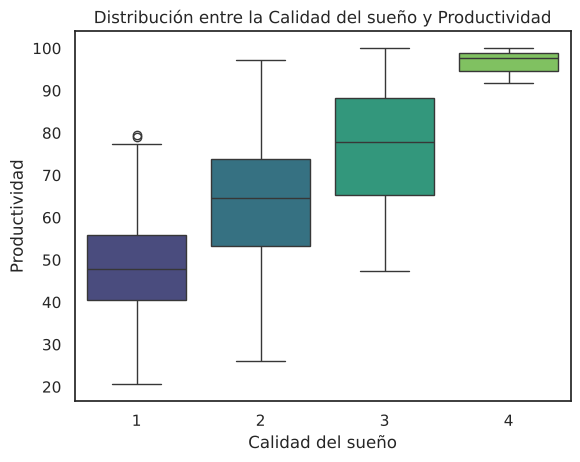

In [54]:
sns.boxplot(x='sleep_quality_1_5', y='productivity_0_100', palette='viridis', data=df)

plt.title("Distribución entre la Calidad del sueño y Productividad")
plt.xlabel("Calidad del sueño")
plt.ylabel("Productividad")

plt.show()

### Ocupaciones vs productividad


Al explorar la relación entre el índice de productividad y las diferentes ocupaciones de la muestra mediante diagramas de caja, los resultados desafían las expectativas convencionales. Se observa una notable uniformidad en las medianas de todos los grupos, fluctuando estrechamente entre los 40 y 70 puntos sobre 100. Ningún grupo ocupacional destaca por tener un rendimiento abrumadoramente superior. Sin embargo, difieren en su dispersión, donde los grupos de retirados y desempleados presentan medianas superiores, en comparación a los empleados y estudiantes, que se concentran en valores más bajos. Además, destacan la cantidad de outliers en los extremos superiores, en especial para la categoría de empleados. Finalmente, esto indica que estudiar o trabajar, no garantiza un mayor nivel de productividad neta frente a quienes no lo están.

/tmp/ipykernel_405/45114039.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='productivity_0_100', y='occupation', palette='viridis', data=df)


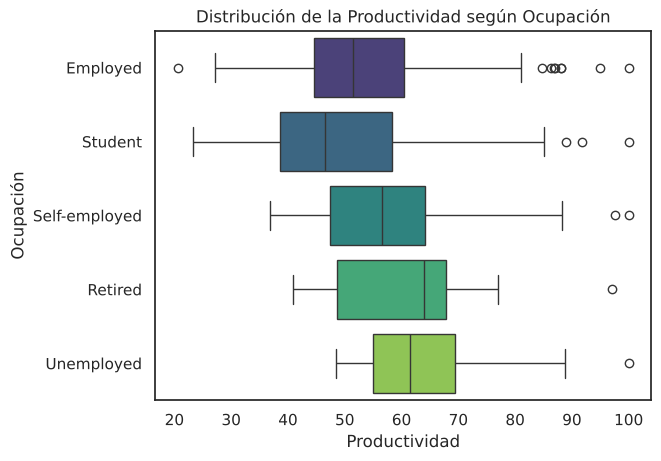

In [55]:
sns.boxplot(x='productivity_0_100', y='occupation', palette='viridis', data=df)

plt.title("Distribución de la Productividad según Ocupación")
plt.xlabel("Productividad")
plt.ylabel("Ocupación")

plt.show()

### Ocupaciones vs niveles de estrés

El gráfico muestra la distribución de los niveles de estrés según la ocupación que cada uno tenga. Se observa que los niveles de estrés son bastantes altos en todos los casos.

Los estudiantes y empleados presentan los niveles más altos de estrés, sobre todo los estudiantes. Estos últimos tienen su mediana muy cercana al 10, por lo que en su mayoría poseen niveles críticos de estrés.

En contraste, los grupos de personas que no tienen empleo o se encuentran retirados, bajan sus niveles de estrés en comparación a los demás grupos.

/tmp/ipykernel_405/2684119603.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stress_level_0_10', y='occupation', palette='viridis', data=df)


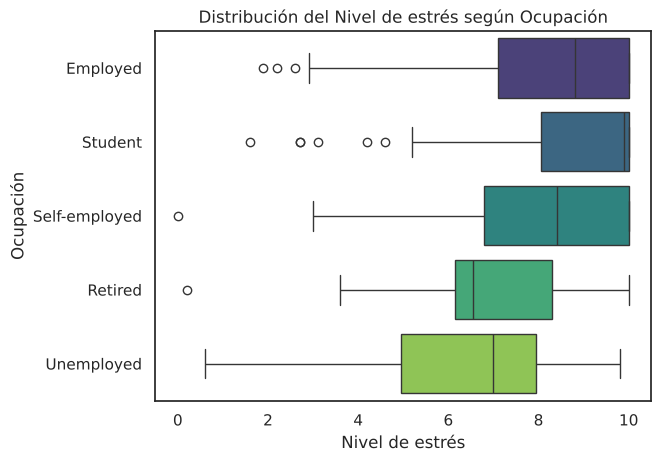

In [56]:
sns.boxplot(x='stress_level_0_10', y='occupation', palette='viridis', data=df)

plt.title("Distribución del Nivel de estrés según Ocupación")
plt.xlabel("Nivel de estrés")
plt.ylabel("Ocupación")

plt.show()

### Ocupaciones vs tiempo en pantalla

/tmp/ipykernel_405/3219021956.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='screen_time_hours', y='occupation', palette='viridis', data=df)


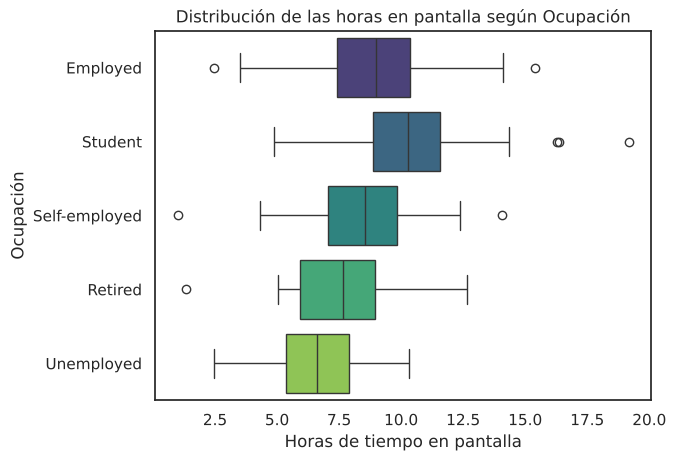

In [57]:
sns.boxplot(x='screen_time_hours', y='occupation', palette='viridis', data=df)

plt.title("Distribución de las horas en pantalla según Ocupación")
plt.xlabel("Horas de tiempo en pantalla")
plt.ylabel("Ocupación")

plt.show()

### Edad vs Tiempo en pantalla total
Se observa una tendencia generacional clara donde los usuarios más jóvenes registran los niveles más altos de consumo digital. Se observan valores atípicos (outliers) en el uso del celular, lo que indica que algunos individuos presentan hábitos significativamente distintos al resto.Existe una correlación negativa débil entre ambas variables, lo que confirma que el uso del dispositivo tiende a disminuir conforme aumenta la edad, posicionando a la juventud como el segmento con mayor intensidad de uso.

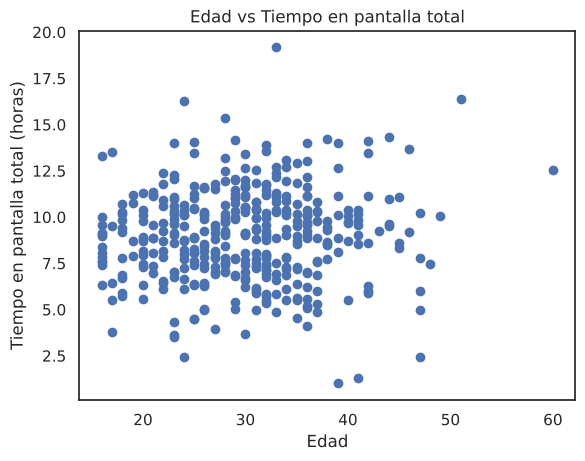

In [58]:
# Carga el archivo CSV y lo guarda en una tabla llamada 'df'
df = pd.read_csv("ScreenTime vs MentalWellness.csv")

# Crea un gráfico de puntos (scatter)
# eje X: edad
# eje Y: tiempo en pantalla total
plt.scatter(df['age'], df['screen_time_hours'])

# Nombre del eje horizontal (X)
plt.xlabel("Edad")

# Nombre del eje vertical (Y)
plt.ylabel("Tiempo en pantalla total (horas)")

# Título del gráfico
plt.title("Edad vs Tiempo en pantalla total")

# Muestra el gráfico en pantalla
plt.show()

### Edad vs tiempo en pantalla en el trabajo
El uso del dispositivo con fines laborales se mantiene estable y constante a través de los distintos rangos etarios, sin mostrar una correlación clara con la edad de los usuarios. Esto sugiere que el consumo de pantalla en el entorno profesional está determinado estrictamente por la naturaleza de la actividad laboral y no por un factor demográfico o generacional.

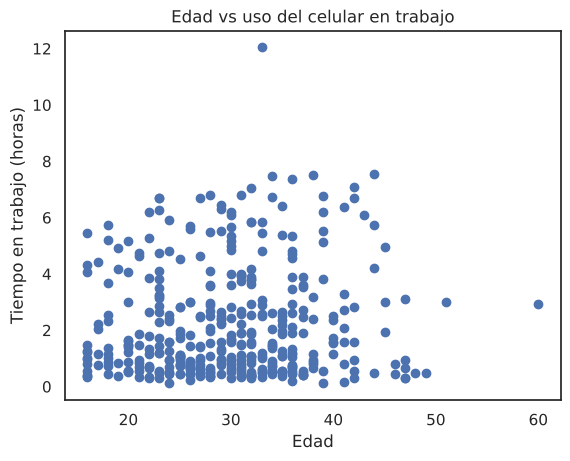

In [59]:
# Crea un gráfico de puntos (scatter)
# eje X: edad de las personas
# eje Y: tiempo que usan el celular en el trabajo
plt.scatter(df['age'], df['work_screen_hours'])

# Nombre del eje horizontal (X)
plt.xlabel("Edad")

# Nombre del eje horizontal (X)
plt.ylabel("Tiempo en trabajo (horas)")

# Título del gráfico
plt.title("Edad vs uso del celular en trabajo")

# Muestra el gráfico en pantalla
plt.show()

### Edad vs Tiempo en pantalla en ocio
Se evidencia una tendencia generacional inversa en el consumo recreativo: mientras los usuarios más jóvenes concentran los niveles más altos de uso, estos valores decrecen de forma constante al aumentar la edad. Esta relación negativa moderada, aunque no es perfectamente lineal, muestra una trayectoria lo suficientemente clara como para confirmar que la edad es un factor determinante en el tiempo dedicado al ocio digital.

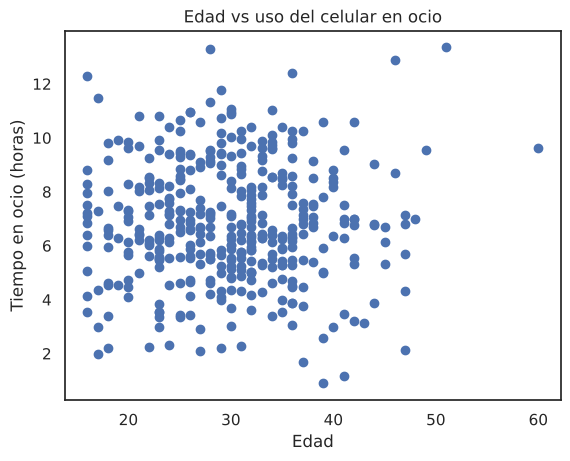

In [60]:
# Crea un gráfico de puntos (scatter)
# eje X: edad de las personas
# eje Y: tiempo que usan el celular en ocio
plt.scatter(df['age'], df['leisure_screen_hours'])

# Nombre del eje horizontal (X)
plt.xlabel("Edad")

# Nombre del eje horizontal (X)
plt.ylabel("Tiempo en ocio (horas)")

# Título del gráfico
plt.title("Edad vs uso del celular en ocio")

# Muestra el gráfico en pantalla
plt.show()

### Productividad vs Tiempo en pantalla
El diagrama de caja confirma una relación negativa moderada-fuerte entre el tiempo de pantalla y la productividad. A medida que aumenta el uso del celular, la mediana de productividad disminuye de forma constante, pasando de niveles óptimos en el uso bajo a niveles deficientes en el uso muy alto. Esto sugiere que el uso excesivo del dispositivo actúa como un factor que impacta directamente en el rendimiento de los usuarios.Se clasificaron los niveles de tiempo en pantalla en categorías cualitativas: “bajo” (0–3), “moderado” (3–6) ,“alto” (6–9) y "muy alto" (9-12), con el objetivo de facilitar la interpretación de los resultados.

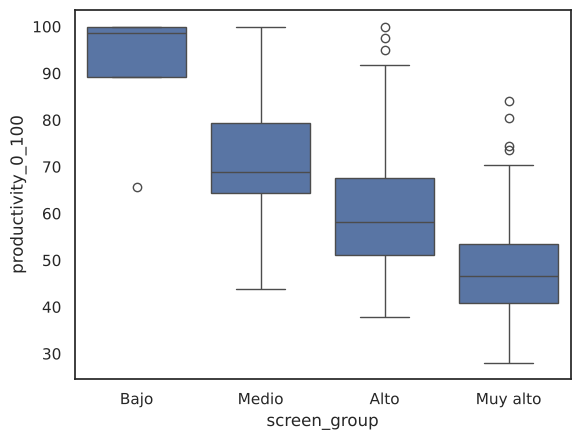

In [61]:
df['screen_group'] = pd.cut(
    # Toma la columna de horas de uso del celular
    df['screen_time_hours'],

    # Define rangos: 0-3, 3-6, 6-9, 9-12 horas
    bins=[0,3,6,9,12],

    # Nombres de cada grupo
    labels=['Bajo','Medio','Alto','Muy alto']
)

# Crea un diagrama de caja
# eje X: grupos de uso del celular
# eje Y: nivel de productividad
# data=df: usa los datos del DataFrame
sns.boxplot(x='screen_group', y='productivity_0_100', data=df)

# Crea un diagrama de caja
# eje X: grupos de uso del celular
# eje Y: nivel de productividad
# data=df: usa los datos del DataFrame
plt.show()

### Estrés vs Ejercicio
El análisis sugiere que el ejercicio podría estar asociado a una reducción del estrés, ya que los grupos con mayor actividad física presentan menores niveles de estrés en promedio. Sin embargo, la variabilidad dentro de cada grupo indica que otros factores también influyen en el nivel de estrés.

La variable exercise_minutes_per_week, originalmente continua, fue dividida en categorías con el objetivo de facilitar su análisis e interpretación. Se definieron los siguientes rangos: bajo (0–50 minutos), medio (50–150 minutos), alto (150–300 minutos) y muy alto (más de 300 minutos semanales).

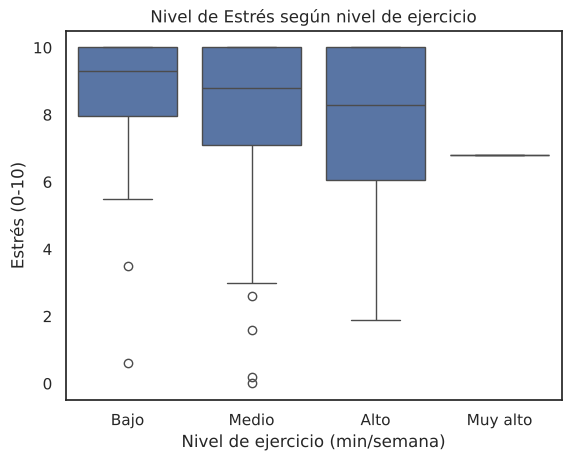

In [62]:

df['exercise_group'] = pd.cut(
    # Toma la columna de minutos de ejercicio
    df['exercise_minutes_per_week'],

    # Toma la columna de minutos de ejercicio
    bins=[0,50,150,300,1000],

    # Nombres de cada grupo
    labels=['Bajo','Medio','Alto','Muy alto']
)

# Crea un diagrama de caja
# eje X: nivel de ejercicio
# eje Y: nivel de estrés
# data=df: usa los datos del DataFrame
sns.boxplot(x='exercise_group', y='stress_level_0_10', data=df)

# Título del gráfico
plt.title("Nivel de Estrés según nivel de ejercicio")

# Título del gráfico
plt.xlabel("Nivel de ejercicio (min/semana)")

# Nombre del eje X
plt.ylabel("Estrés (0-10)")

# Nombre del eje Y
plt.show()

# Formulación de hipótesis/pregunta

## ¿En qué medida la cantidad de horas en pantalla y la calidad del sueño se relacionan con los niveles de estrés, según la ocupación que posea la muestra?

La motivación para escoger esta pregunta sobre el dataset, es haber encontrado en la muestra que los niveles de estrés se concentraban en valores muy altos, además, de haber descubierto que los estudiantes y empleados presentan mayores niveles de estrés que los desempleados o retirados, por lo que es interesante conocer la relación que tienen con otras variables como, las horas en pantalla y la calidad del sueño.